# M2: Conditional generation experiments

The experiment uses 12 fixed validation captions with seeds `s`, `s+1000`, `s+2000`, for 36 paired inputs per configuration. The test split is held out.

Study A uses eight predefined configurations that vary guidance (3/7.5/12), requested steps (20/30/50), sampler (PNDM/DDIM), DDIM timestep spacing (leading/trailing), and selected-token weight (1/1.2). DDIM uses `eta=0`. Study A retains the checkpoint's `scaled_linear` beta schedule.

A separate beta-schedule study below adds 108 outputs comparing scaled-linear, linear and cosine with the checkpoint frozen.


In [1]:
from pathlib import Path
import json
import p2_pipeline as p2
import p2_experiments as m2
import p2_noise_schedule as noise

cfg = m2.settings()
data_config = p2.load_config(m2.ROOT / "config.json")
data_config["dataset_dir"] = cfg["dataset_dir"]
env = m2.environment()
print(json.dumps(env, indent=2))
assert env.get("cuda_available"), "CUDA is required for inference."
assert env["packages"]["diffusers"] == "0.32.2"


{
  "python": "3.10.16",
  "executable": "/opt/miniconda/envs/eai/bin/python",
  "platform": "Linux-5.14.0-362.13.1.el9_3.x86_64-x86_64-with-glibc2.35",
  "packages": {
    "torch": "2.5.1",
    "diffusers": "0.32.2",
    "transformers": "4.49.0",
    "accelerate": "1.5.2",
    "numpy": "1.26.4",
    "Pillow": "11.1.0",
    "huggingface-hub": "0.29.3",
    "safetensors": "0.5.3",
    "ipykernel": "6.29.5"
  },
  "cuda_available": true,
  "torch_cuda": "12.1",
  "gpu": "Tesla P100-PCIE-12GB",
  "gpu_total_gib": 11.907958984375
}


In [2]:
prompts = m2.fixed_inputs(cfg, data_config)
print("Baseline validation:", noise.baseline_gate(cfg, data_config, prompts, env))
for name, spec in m2.configurations(cfg).items():
    print(name, spec)
print("Planned outputs:", len(prompts) * len(cfg["seed_offsets"]) * len(m2.configurations(cfg)))


Baseline validation: {'smoke': {'samples_verified': 8, 'runtime': {'compatible': True, 'differences': {'gpu': {'recorded': 'Tesla V100-SXM2-32GB', 'current': 'Tesla P100-PCIE-12GB'}, 'gpu_total_gib': {'recorded': 31.7393798828125, 'current': 11.907958984375}}}, 'signature_sha256': '16c1943e5f24f1a3b0c2f77167cd777a9718bf671570aca7f8da26d63b0d935a'}, 'sweep': {'samples_verified': 288, 'runtime': {'compatible': True, 'differences': {'gpu': {'recorded': 'Tesla V100-SXM2-32GB', 'current': 'Tesla P100-PCIE-12GB'}, 'gpu_total_gib': {'recorded': 31.7393798828125, 'current': 11.907958984375}}}, 'signature_sha256': '5ece6a6f73121c574aa7699312e6412925c61f1a54b8293c63c5337e530db7a6'}}
B {'guidance': 7.5, 'steps': 30, 'sampler': 'PNDM', 'spacing': 'leading', 'weight': 1.0}
G-low {'guidance': 3.0, 'steps': 30, 'sampler': 'PNDM', 'spacing': 'leading', 'weight': 1.0}
G-high {'guidance': 12.0, 'steps': 30, 'sampler': 'PNDM', 'spacing': 'leading', 'weight': 1.0}
T-short {'guidance': 7.5, 'steps': 20, 's

In [3]:
run = m2.path_from_root(cfg["sweep_dir"])
result = p2.read_json(run / "summary.json")
print(json.dumps(result, indent=2))
records = m2.verify_phase(cfg, "sweep")
assert len(records) == 288


{
  "status": "complete",
  "phase": "sweep",
  "sample_count": 288,
  "training_performed": false,
  "configurations": {
    "B": {
      "guidance": 7.5,
      "steps": 30,
      "sampler": "PNDM",
      "spacing": "leading",
      "weight": 1.0
    },
    "G-low": {
      "guidance": 3.0,
      "steps": 30,
      "sampler": "PNDM",
      "spacing": "leading",
      "weight": 1.0
    },
    "G-high": {
      "guidance": 12.0,
      "steps": 30,
      "sampler": "PNDM",
      "spacing": "leading",
      "weight": 1.0
    },
    "T-short": {
      "guidance": 7.5,
      "steps": 20,
      "sampler": "PNDM",
      "spacing": "leading",
      "weight": 1.0
    },
    "T-long": {
      "guidance": 7.5,
      "steps": 50,
      "sampler": "PNDM",
      "spacing": "leading",
      "weight": 1.0
    },
    "S-DDIM": {
      "guidance": 7.5,
      "steps": 30,
      "sampler": "DDIM",
      "spacing": "leading",
      "weight": 1.0
    },
    "N-trailing": {
      "guidance": 7.5,
      "step

## Runtime and sampler diagnostics

A separate five-step warm-up is excluded from the 288 experimental outputs and resource tables.


In [4]:
from statistics import mean, median

resource_rows = []
for name, spec in m2.configurations(cfg).items():
    group = [r for r in records if r["inputs"]["configuration"] == spec]
    row = {"configuration": name, "n": len(group), "mean_s": round(mean(r["seconds"] for r in group), 3),
                 "median_s": round(median(r["seconds"] for r in group), 3),
                 "peak_GiB": round(max(r["peak_allocated_gib"] for r in group), 3),
                 "U-Net_calls": sorted({r["unet_calls"] for r in group}),
                 "flagged": sum(r["nsfw_content_detected"] for r in group)}
    resource_rows.append(row)
    print(row)
p2.write_json(run / "resource_summary.json", resource_rows)
print(result["timing_scope"])


{'configuration': 'B', 'n': 36, 'mean_s': 2.129, 'median_s': 2.13, 'peak_GiB': 3.06, 'U-Net_calls': [31], 'flagged': 0}
{'configuration': 'G-low', 'n': 36, 'mean_s': 2.135, 'median_s': 2.134, 'peak_GiB': 3.06, 'U-Net_calls': [31], 'flagged': 0}
{'configuration': 'G-high', 'n': 36, 'mean_s': 2.133, 'median_s': 2.131, 'peak_GiB': 3.06, 'U-Net_calls': [31], 'flagged': 0}
{'configuration': 'T-short', 'n': 36, 'mean_s': 1.473, 'median_s': 1.473, 'peak_GiB': 3.06, 'U-Net_calls': [21], 'flagged': 0}
{'configuration': 'T-long', 'n': 36, 'mean_s': 3.446, 'median_s': 3.446, 'peak_GiB': 3.06, 'U-Net_calls': [51], 'flagged': 0}
{'configuration': 'S-DDIM', 'n': 36, 'mean_s': 2.068, 'median_s': 2.067, 'peak_GiB': 3.06, 'U-Net_calls': [30], 'flagged': 0}
{'configuration': 'N-trailing', 'n': 36, 'mean_s': 2.069, 'median_s': 2.067, 'peak_GiB': 3.06, 'U-Net_calls': [30], 'flagged': 0}
{'configuration': 'C', 'n': 36, 'mean_s': 2.131, 'median_s': 2.13, 'peak_GiB': 3.06, 'U-Net_calls': [31], 'flagged': 0}


In [5]:
import numpy as np

run = m2.path_from_root(cfg["sweep_dir"])
for name in m2.configurations(cfg):
    r = p2.read_json(run / "generated" / f"{name}_01_7615.json")
    with np.load(run / r["diagnostics"], allow_pickle=False) as trace:
        print(name, "timesteps:", r["timesteps"])
        print("rms(first,last):", trace["stats"][[0, -1], 0].tolist(),
              "mean update rms:", float(trace["stats"][1:, 2].mean()))


B timesteps: [958, 925, 925, 892, 859, 826, 793, 760, 727, 694, 661, 628, 595, 562, 529, 496, 463, 430, 397, 364, 331, 298, 265, 232, 199, 166, 133, 100, 67, 34, 1]
rms(first,last): [1.0001575946807861, 1.0224257707595825] mean update rms: 0.05518385395407677
G-low timesteps: [958, 925, 925, 892, 859, 826, 793, 760, 727, 694, 661, 628, 595, 562, 529, 496, 463, 430, 397, 364, 331, 298, 265, 232, 199, 166, 133, 100, 67, 34, 1]
rms(first,last): [0.9999116063117981, 0.9382029175758362] mean update rms: 0.032904788851737976
G-high timesteps: [958, 925, 925, 892, 859, 826, 793, 760, 727, 694, 661, 628, 595, 562, 529, 496, 463, 430, 397, 364, 331, 298, 265, 232, 199, 166, 133, 100, 67, 34, 1]
rms(first,last): [1.0004794597625732, 1.1031910181045532] mean update rms: 0.07666337490081787
T-short timesteps: [951, 901, 901, 851, 801, 751, 701, 651, 601, 551, 501, 451, 401, 351, 301, 251, 201, 151, 101, 51, 1]
rms(first,last): [0.9998714327812195, 1.0066838264465332] mean update rms: 0.08839830011

## Paired gallery

The complete gallery contains all 288 outputs in 36 prompt/seed comparisons, with parameter labels and safety flags. It is saved as a standalone HTML file with embedded JPEG previews; original PNGs remain unchanged. The notebook shows three original-seed comparisons: prompts 2, 3 and 12.


In [6]:
import base64
import html
import io
from PIL import Image, ImageDraw

def comparison_image(prompt, offset):
    seed = prompt["seed"] + offset
    sheet = Image.new("RGB", (1024, 600), "white")
    draw = ImageDraw.Draw(sheet)
    sources = []
    for i, (name, spec) in enumerate(m2.configurations(cfg).items()):
        record = next(r for r in records if
                      r["inputs"]["prompt_record"]["index"] == prompt["index"]
                      and r["inputs"]["seed"] == seed
                      and r["inputs"]["configuration"] == spec)
        x, y = (i % 4) * 256, (i // 4) * 300
        with Image.open(run / record["image"]) as image:
            sheet.paste(image.resize((256, 256)), (x, y + 44))
        label = f"{name} g={spec['guidance']} n={spec['steps']} w={spec['weight']}\n{spec['sampler']} {spec['spacing']}"
        if record["nsfw_content_detected"]:
            label += " FLAGGED"
        draw.text((x + 4, y + 2), label, fill="black")
        sources.append({"configuration": name, "image": record["image"],
                        "image_sha256": record["image_sha256"],
                        "flagged": record["nsfw_content_detected"]})
    buffer = io.BytesIO()
    sheet.save(buffer, format="JPEG", quality=85)
    return buffer.getvalue(), sources

gallery = run / "gallery.html"
partial = gallery.with_suffix(".html.partial")
entries, previews = [], {}
with partial.open("w", encoding="utf-8") as output:
    output.write('<!doctype html><html lang="en"><meta charset="utf-8">'
                 '<title>M2 paired gallery</title><style>'
                 'body{font:16px sans-serif;max-width:1050px;margin:24px auto;padding:12px}'
                 'figure{margin:24px 0;break-inside:avoid}img{width:100%;height:auto}'
                 'figcaption{margin-bottom:8px}</style><body><h1>M2 paired gallery</h1>'
                 '<p>288 samples: 8 configurations, 12 prompts, 3 seeds.</p>')
    for offset in cfg["seed_offsets"]:
        for prompt in prompts:
            seed = prompt["seed"] + offset
            jpeg, sources = comparison_image(prompt, offset)
            title = f"{prompt['index']:02d} | seed {seed} | {prompt['prompt']}"
            escaped = html.escape(title, quote=True)
            encoded = base64.b64encode(jpeg).decode("ascii")
            output.write(f'<figure><figcaption>{escaped}</figcaption>'
                         f'<img alt="{escaped}" src="data:image/jpeg;base64,{encoded}"></figure>')
            entries.append({"prompt_id": prompt["index"], "prompt": prompt["prompt"],
                            "seed": seed, "sources": sources})
            if offset == 0 and prompt["index"] in (2, 3, 12):
                previews[prompt["index"]] = jpeg
    output.write('</body></html>')
assert len(entries) == 36 and sum(len(e["sources"]) for e in entries) == 288
partial.replace(gallery)
p2.write_json(run / "gallery_index.json", {"gallery": "gallery.html",
              "gallery_sha256": p2.sha256(gallery), "sample_count": 288, "groups": entries})
print("Saved:", gallery, "| 36 comparisons, 288 samples")


Saved: /home/zhang.jiaso/ondemand/data/sys/dashboard/batch_connect/sys/jupyterlab-ml-courses/ie7615-project2/results/m2_sweep_v1/gallery.html | 36 comparisons, 288 samples


02 | seed 7616 | A child taking a bite of a pizza slice on a plate.


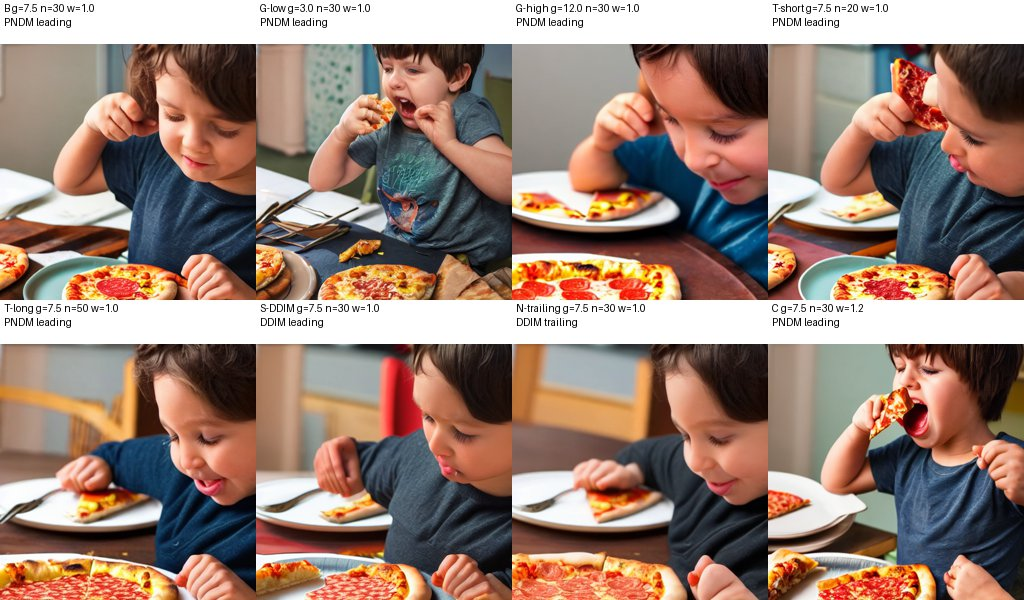

03 | seed 7617 | Two computers are sitting on top of the desk.


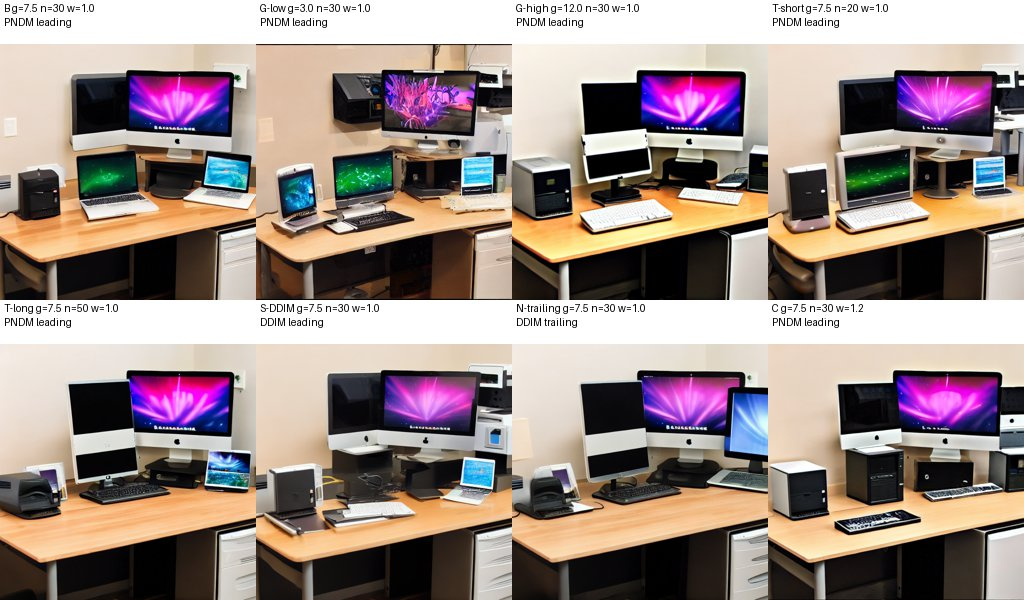

12 | seed 7626 | A dog laying on grass near a flying disc.


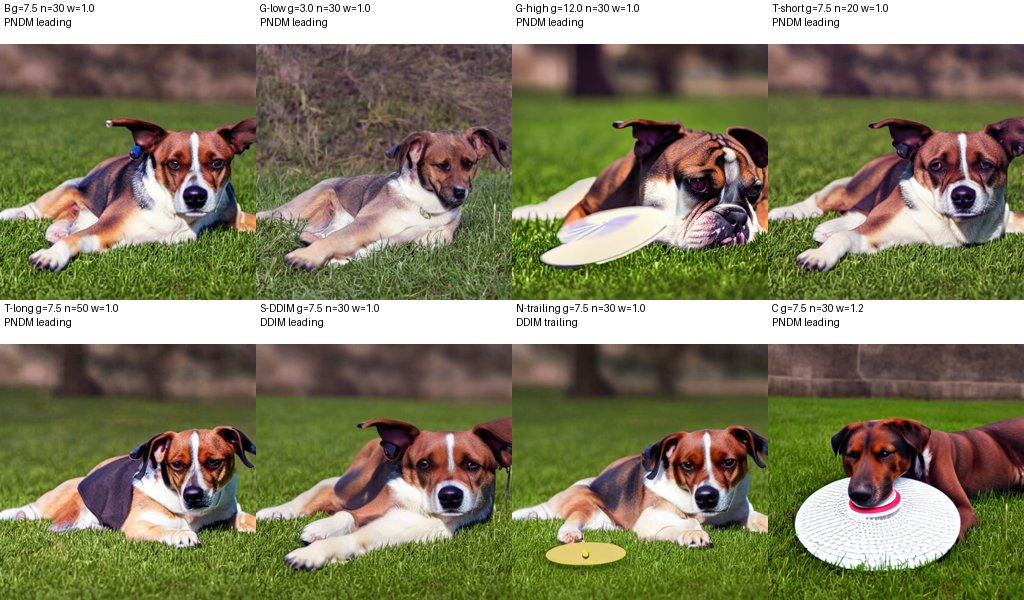

In [7]:
from IPython.display import Image as NotebookImage, display

for prompt_id in (2, 3, 12):
    prompt = next(p for p in prompts if p["index"] == prompt_id)
    print(f"{prompt_id:02d} | seed {prompt['seed']} | {prompt['prompt']}")
    display(NotebookImage(data=previews[prompt_id], format="jpeg"))


## Comparisons

B/G-low/G-high isolate guidance; T-short/B/T-long isolate step count; B/S-DDIM compare samplers; S-DDIM/N-trailing isolate timestep spacing; B/C isolate token reweighting. Three seeds per prompt support visual comparison of variation. This design does not estimate interactions between factors.

Runtime includes denoising diagnostics, VAE decoding and safety checking; it excludes text encoding, loading and file saving. Latent statistics describe sampling behavior, not image quality scores.



## Beta schedule sensitivity

DDIM uses 30 steps, guidance 7.5, leading spacing, eta 0 and token weight 1. The three beta schedules are `scaled_linear`, `linear` and cosine (`squaredcos_cap_v2`), with the same 12 captions and three seeds: 108 outputs. Warm-ups are excluded.

The checkpoint was trained with `scaled_linear` and remains frozen. This measures inference beta-schedule sensitivity, including training/inference mismatch, rather than comparing separately trained models.


In [8]:
import p2_noise_schedule as noise

noise_result = noise.run(cfg, data_config)
print(json.dumps(noise_result, indent=2))
noise_records = noise.verify(cfg, data_config)
noise_run = noise.run_path(data_config)
assert len(noise_records) == 108


2026-11-09 06:39:43.878845: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1794224384.058697 4112810 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1794224384.104045 4112810 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1794224384.599543 4112810 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1794224384.599576 4112810 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1794224384.599578 4112810 computation_placer.cc:177] computation placer alr

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Six pilot outputs verified; continuing paired comparisons.
1/108 N-scaled prompt=1 seed=7615
2/108 N-scaled prompt=1 seed=8615
3/108 N-scaled prompt=1 seed=9615
4/108 N-scaled prompt=2 seed=7616
5/108 N-scaled prompt=2 seed=8616
6/108 N-scaled prompt=2 seed=9616
7/108 N-scaled prompt=3 seed=7617
8/108 N-scaled prompt=3 seed=8617
9/108 N-scaled prompt=3 seed=9617
10/108 N-scaled prompt=4 seed=7618
11/108 N-scaled prompt=4 seed=8618
12/108 N-scaled prompt=4 seed=9618
13/108 N-scaled prompt=5 seed=7619
14/108 N-scaled prompt=5 seed=8619
15/108 N-scaled prompt=5 seed=9619
16/108 N-scaled prompt=6 seed=7620
17/108 N-scaled prompt=6 seed=8620
18/108 N-scaled prompt=6 seed=9620
19/108 N-scaled prompt=7 seed=7621
20/108 N-scaled prompt=7 seed=8621
21/108 N-scaled prompt=7 seed=9621
22/108 N-scaled prompt=8 seed=7622
23/108 N-scaled prompt=8 seed=8622
24/108 N-scaled prompt=8 seed=9622
25/108 N-scaled prompt=9 seed=7623
26/108 N-scaled prompt=9 seed=8623
27/108 N-scaled prompt=9 seed=9623
28/10

In [9]:
noise_resources = []
for name, spec in noise.configurations().items():
    group = [r for r in noise_records if r["inputs"]["configuration"] == spec]
    row = {"configuration": name, "beta_schedule": spec["beta_schedule"], "n": len(group),
           "mean_s": round(mean(r["seconds"] for r in group), 3),
           "median_s": round(median(r["seconds"] for r in group), 3),
           "peak_GiB": round(max(r["peak_allocated_gib"] for r in group), 3),
           "U-Net_calls": sorted({r["unet_calls"] for r in group}),
           "flagged": sum(r["nsfw_content_detected"] for r in group)}
    noise_resources.append(row)
    print(row)
p2.write_json(noise_run / "resource_summary.json", noise_resources)
print(noise_result["timing_scope"])
for curve in p2.read_json(noise_run / "curves.json"):
    with np.load(noise_run / curve["file"], allow_pickle=False) as arrays:
        print(curve["configuration"], "beta(first,last):", curve["beta_first"], curve["beta_last"])
        print("SNR at t=0,250,500,750,999:", arrays["snr"][[0, 250, 500, 750, 999]].tolist())


{'configuration': 'N-scaled', 'beta_schedule': 'scaled_linear', 'n': 36, 'mean_s': 9.976, 'median_s': 9.975, 'peak_GiB': 3.449, 'U-Net_calls': [30], 'flagged': 0}
{'configuration': 'N-linear', 'beta_schedule': 'linear', 'n': 36, 'mean_s': 9.977, 'median_s': 9.977, 'peak_GiB': 3.449, 'U-Net_calls': [30], 'flagged': 0}
{'configuration': 'N-cosine', 'beta_schedule': 'squaredcos_cap_v2', 'n': 36, 'mean_s': 9.979, 'median_s': 9.979, 'peak_GiB': 3.449, 'U-Net_calls': [30], 'flagged': 0}
pipeline call including diagnostics, VAE and safety; excludes encoding/save/load
N-scaled beta(first,last): 0.0008499999530613422 0.011999999172985554
SNR at t=0,250,500,750,999: [1175.440361825959, 2.065531586153265, 0.3818500284961202, 0.05951261618321454, 0.004681913249119404]
N-linear beta(first,last): 0.0008500000112690032 0.012000000104308128
SNR at t=0,250,500,750,999: [1175.440361825959, 1.3190452020696282, 0.19157076632365502, 0.02303802369977213, 0.0015814598458379148]
N-cosine beta(first,last): 4.1

The saved beta, cumulative-alpha and SNR arrays record the schedules used for inference. The cosine schedule constructs its own beta curve, with the endpoints printed above.


Saved: /home/zhang.jiaso/ondemand/data/sys/dashboard/batch_connect/sys/jupyterlab-ml-courses/ie7615-project2/results/m2_noise_schedule_v1/gallery.html | 36 comparisons, 108 samples
02 | seed 7616 | A child taking a bite of a pizza slice on a plate.


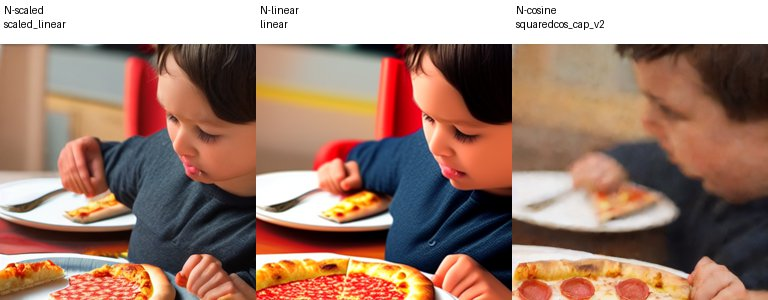

03 | seed 7617 | Two computers are sitting on top of the desk.


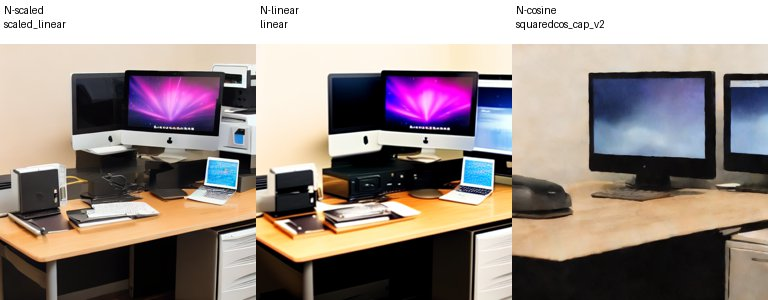

12 | seed 7626 | A dog laying on grass near a flying disc.


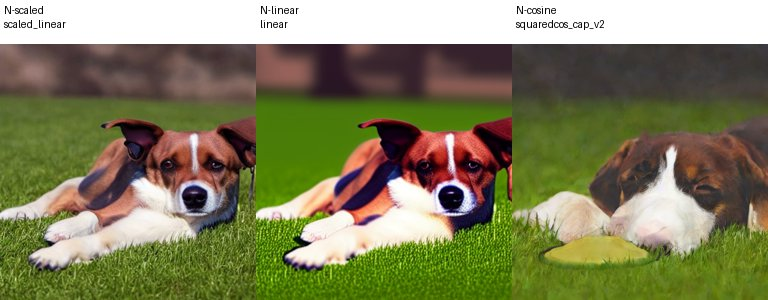

In [10]:
noise_previews = noise.gallery(cfg, data_config, noise_records)
print("Saved:", noise_run / "gallery.html", "| 36 comparisons, 108 samples")
for prompt_id in (2, 3, 12):
    prompt = next(p for p in prompts if p["index"] == prompt_id)
    print(f"{prompt_id:02d} | seed {prompt['seed']} | {prompt['prompt']}")
    display(NotebookImage(data=noise_previews[prompt_id], format="jpeg"))


Mean inference times per image were 9.976 s for scaled-linear, 9.977 s for linear, and 9.979 s for cosine. Each group reached approximately 3.449 GiB of peak allocated memory.

In the displayed comparisons, linear makes the pizza and grass more saturated. Cosine softens the child's facial detail in prompt 2, shows fewer devices on the desk in prompt 3, and makes a disc-like object more visible beside the dog in prompt 12. The biting action and the exact number of computers remain unclear.
